In [9]:
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

In [10]:

# Configurazione matplotlib per il supporto PGF / LaTeX
matplotlib.rcParams.update({
    "pgf.texsystem": "pdflatex",
    "font.family": "serif",
    "text.usetex": False,  # Impostare a True se LaTeX è installato nel sistema
})


=================== R'1 ===================
File: scope_R'1.csv
R'1/R teorico = 4.541 (13.143 dB)
A0 misurato = 4.699 +/- 0.06 (13.441 dB)
fc = 4.164e+05 +/- 1e+04 Hz
GBW = 1.957e+06 +/- 3.8e+04 Hz
RMSE del fit = 1.23 dB


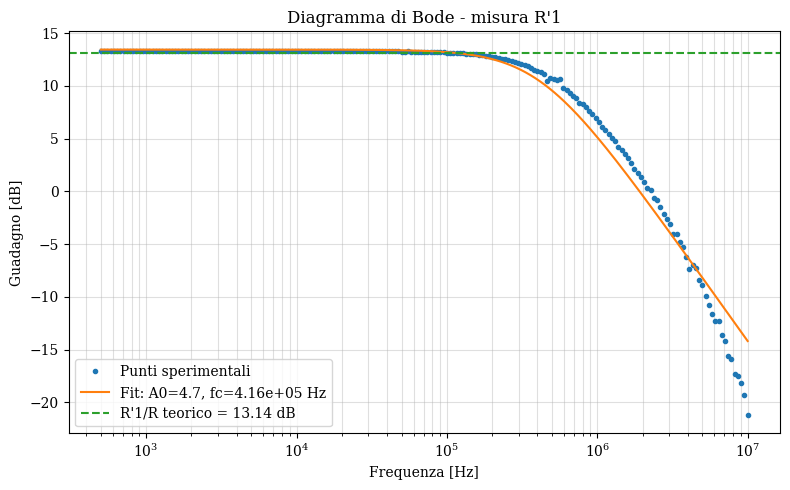


=================== R'2 ===================
File: scope_R'2.csv
R'2/R teorico = 9.574 (19.622 dB)
A0 misurato = 47.65 +/- 0.94 (33.561 dB)
fc = 4.657e+04 +/- 1.3e+03 Hz
GBW = 2.219e+06 +/- 4e+04 Hz
RMSE del fit = 1.53 dB


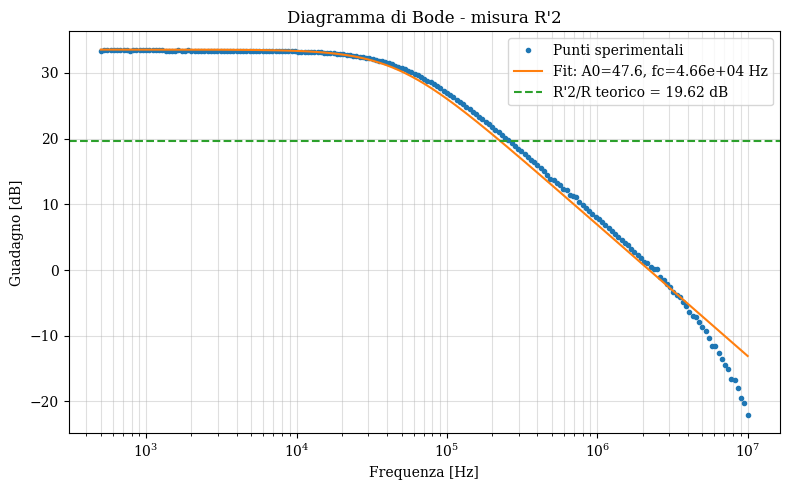


=================== R'3 ===================
File: scope_R'3.csv
R'3/R teorico = 21.48 (26.641 dB)
A0 misurato = 100.8 +/- 2.1 (40.066 dB)
fc = 2.266e+04 +/- 6.3e+02 Hz
GBW = 2.283e+06 +/- 3.7e+04 Hz
RMSE del fit = 1.47 dB


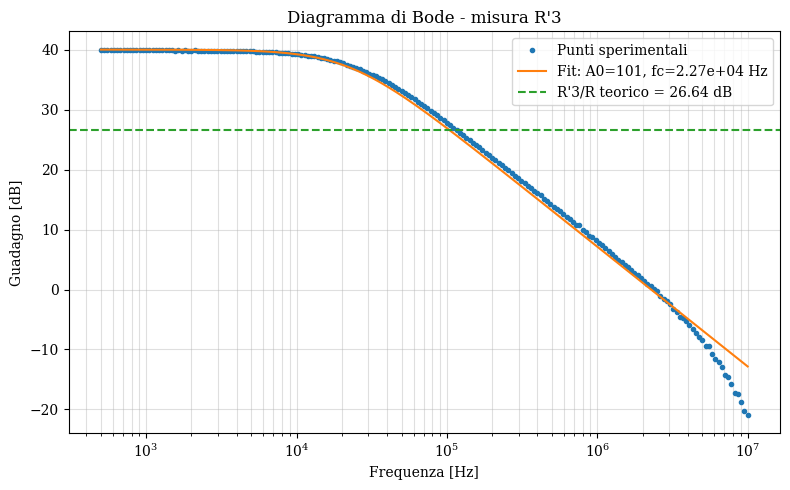


=================== R'4 ===================
File: scope_R'4.csv
R'4/R teorico = 45.49 (33.158 dB)
A0 misurato = 326.1 +/- 0.18 (50.266 dB)
fc = 7800 +/- 6.4 Hz
GBW = 2.543e+06 +/- 1.3e+03 Hz
RMSE del fit = 0.0442 dB


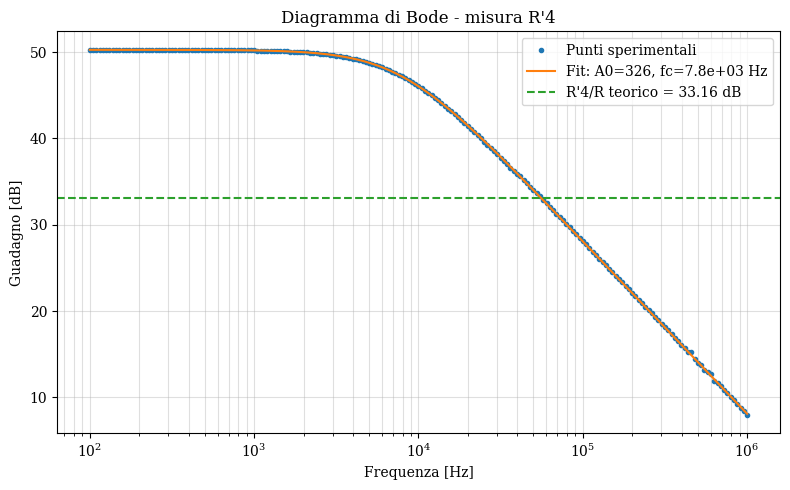

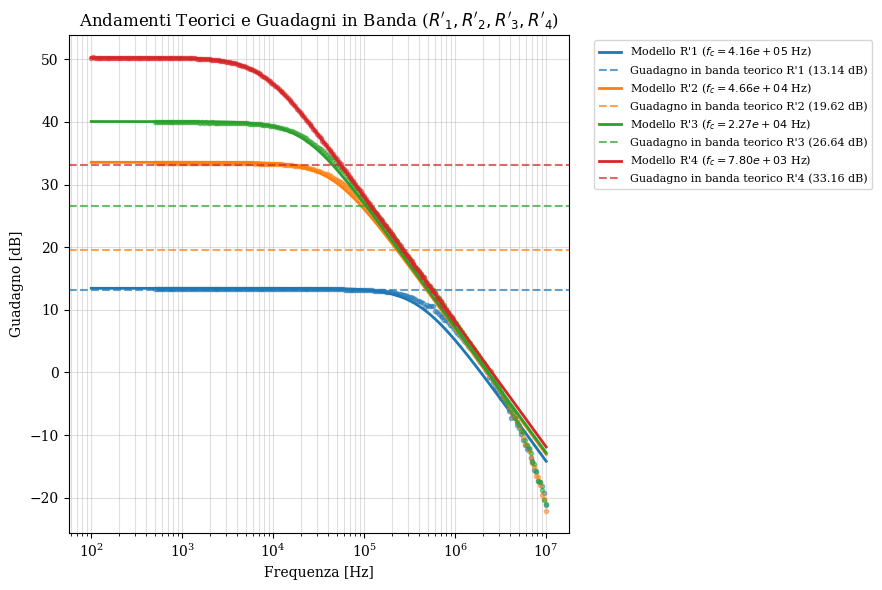

In [11]:
DB = 20.0 / np.log(10.0)
R = 1.0288e3  # Resistenza R comune a tutte le misure

# Configurazione delle 4 misure con i rispettivi valori di R' e file CSV
MISURE = [
    {"nome": "R'1", "R_primo": 4.672e3, "csv": Path.cwd() / "scope_R'1.csv"},
    {"nome": "R'2", "R_primo": 9.850e3, "csv": Path.cwd() / "scope_R'2.csv"},  # Inserire valore reale di R'_2
    {"nome": "R'3", "R_primo": 22.10e3, "csv": Path.cwd() / "scope_R'3.csv"},  # Inserire valore reale di R'_3
    {"nome": "R'4", "R_primo": 46.80e3, "csv": Path.cwd() / "scope_R'4.csv"},  # Inserire valore reale di R'_4
]


def salva_grafico(nome_base: str):
    """Salva la figura corrente in formato PNG, PDF e PGF (compatibile LaTeX)."""
    plt.savefig(f"{nome_base}.png", dpi=300, bbox_inches="tight")
    plt.savefig(f"{nome_base}.pdf", bbox_inches="tight")
    try:
        plt.savefig(f"{nome_base}.pgf", bbox_inches="tight")
    except Exception as e:
        print(f"Nota: Impossibile esportare in .pgf per {nome_base}: {e}")


def modello(f, A0, fc):
    return A0 / np.sqrt(1 + (f / fc) ** 2)


def modello_db(f, A0, fc):
    return DB * np.log(modello(f, A0, fc))


def carica(csv):
    dati = np.genfromtxt(
        csv,
        delimiter=",",
        skip_header=1,
        usecols=(1, 3),
        dtype=float,
        encoding="latin1",
    )
    if dati.ndim != 2 or dati.shape[1] != 2 or dati.shape[0] < 3:
        raise ValueError(f"Il CSV {csv} non contiene abbastanza dati validi.")

    frequenza, guadagno_db = dati.T
    validi = np.isfinite(frequenza) & np.isfinite(guadagno_db) & (frequenza > 0)
    frequenza, guadagno_db = frequenza[validi], guadagno_db[validi]
    if frequenza.size < 3:
        raise ValueError(f"Il CSV {csv} deve contenere almeno tre misure valide.")
    return frequenza, guadagno_db


def fit_bode(frequenza, guadagno_db):
    livello_bassa_f = np.mean(guadagno_db[:3])
    A0_iniziale = 10 ** (livello_bassa_f / 20)
    fc_iniziale = frequenza[
        np.argmin(np.abs(guadagno_db - (livello_bassa_f - 3.0)))
    ]
    parametri, covarianza = curve_fit(
        modello_db,
        frequenza,
        guadagno_db,
        p0=[A0_iniziale, fc_iniziale],
        bounds=(0, np.inf),
        maxfev=20000,
    )
    errori = np.sqrt(np.diag(covarianza))
    A0, fc = parametri
    gbw = A0 * fc
    errore_gbw = np.sqrt(
        (fc * errori[0]) ** 2
        + (A0 * errori[1]) ** 2
        + 2 * A0 * fc * covarianza[0, 1]
    )
    residui = guadagno_db - modello_db(frequenza, *parametri)
    rmse_db = np.sqrt(np.mean(residui**2))
    return parametri, errori, gbw, errore_gbw, rmse_db


def analizza_misura(nome, R_primo, csv):
    if not csv.exists():
        print(f"File non trovato: {csv}")
        return None

    frequenza, guadagno_db = carica(csv)
    parametri, errori, gbw, errore_gbw, rmse_db = fit_bode(
        frequenza, guadagno_db
    )
    A0, fc = parametri
    guadagno_teorico = R_primo / R
    guadagno_teorico_db = 20 * np.log10(guadagno_teorico)

    print(f"\n=================== {nome} ===================")
    print(f"File: {csv.name}")
    print(f"{nome}/R teorico = {guadagno_teorico:.4g} ({guadagno_teorico_db:.3f} dB)")
    print(f"A0 misurato = {A0:.4g} +/- {errori[0]:.2g} ({20*np.log10(A0):.3f} dB)")
    print(f"fc = {fc:.4g} +/- {errori[1]:.2g} Hz")
    print(f"GBW = {gbw:.4g} +/- {errore_gbw:.2g} Hz")
    print(f"RMSE del fit = {rmse_db:.3g} dB")

    # Grafico singolo per misura
    frequenza_fit = np.logspace(
        np.log10(frequenza.min()), np.log10(frequenza.max()), 400
    )
    plt.figure(figsize=(8, 5))
    plt.plot(frequenza, guadagno_db, "o", ms=3, label="Punti sperimentali")
    plt.plot(
        frequenza_fit,
        modello_db(frequenza_fit, *parametri),
        "-",
        label=f"Fit: A0={A0:.3g}, fc={fc:.3g} Hz",
    )
    plt.axhline(
        guadagno_teorico_db,
        color="tab:green",
        linestyle="--",
        label=f"{nome}/R teorico = {guadagno_teorico_db:.2f} dB",
    )
    plt.xscale("log")
    plt.xlabel("Frequenza [Hz]")
    plt.ylabel("Guadagno [dB]")
    plt.title(f"Diagramma di Bode - misura {nome}")
    plt.grid(True, which="both", alpha=0.4)
    plt.legend()
    plt.tight_layout()

    nome_clean = nome.replace("'", "")
    salva_grafico(f"bode_{nome_clean}")
    plt.show()

    return {
        "nome": nome,
        "R_primo": R_primo,
        "frequenza": frequenza,
        "guadagno_db": guadagno_db,
        "parametri": parametri,
        "guadagno_teorico_db": guadagno_teorico_db,
        "guadagno_misurato_db": 20 * np.log10(A0),
    }


def grafico_teorico_e_banda(risultati):
    """Genera il grafico con gli andamenti teorici e le rette orizzontali del guadagno in banda."""
    plt.figure(figsize=(9, 6))

    # Range di frequenza comune esteso per mostrare la risposta in frequenza completa
    f_min = min(res["frequenza"].min() for res in risultati if res)
    f_max = max(res["frequenza"].max() for res in risultati if res)
    frequenze_teoriche = np.logspace(np.log10(f_min), np.log10(f_max), 500)

    colori = plt.cm.tab10.colors

    for idx, res in enumerate(risultati):
        if res is None:
            continue
        nome = res["nome"]
        A0, fc = res["parametri"]
        g_teorico_db = res["guadagno_teorico_db"]
        g_misurato_db = res["guadagno_misurato_db"]
        color = colori[idx % len(colori)]

        # 1. Curve teoriche basate sui parametri ricavati dal fit
        guadagno_modello = modello_db(frequenze_teoriche, A0, fc)
        plt.plot(
            frequenze_teoriche,
            guadagno_modello,
            "-",
            color=color,
            linewidth=2,
            label=f"Modello {nome} ($f_c={fc:.2e}$ Hz)",
        )

        # 2. Rette orizzontali del guadagno in banda a bassa frequenza (Teorico)
        plt.axhline(
            g_teorico_db,
            color=color,
            linestyle="--",
            alpha=0.7,
            label=f"Guadagno in banda teorico {nome} ({g_teorico_db:.2f} dB)",
        )

        # 3. Punti sperimentali sovrapposti (opzionali per riscontro visuale)
        plt.plot(
            res["frequenza"],
            res["guadagno_db"],
            "o",
            color=color,
            ms=3,
            alpha=0.5,
        )

    plt.xscale("log")
    plt.xlabel("Frequenza [Hz]")
    plt.ylabel("Guadagno [dB]")
    plt.title("Andamenti Teorici e Guadagni in Banda ($R'_1, R'_2, R'_3, R'_4$)")
    plt.grid(True, which="both", alpha=0.4)
    plt.legend(bbox_to_anchor=(1.04, 1), loc="upper left", fontsize=8)
    plt.tight_layout()

    salva_grafico("bode_teorico_e_banda")
    plt.show()


if __name__ == "__main__":
    risultati = []
    for m in MISURE:
        res = analizza_misura(nome=m["nome"], R_primo=m["R_primo"], csv=m["csv"])
        if res is not None:
            risultati.append(res)

    if risultati:
        grafico_teorico_e_banda(risultati)

In [12]:
"""Calcolo dello slew rate dai valori misurati con i cursori."""

from dataclasses import dataclass


@dataclass
class Gamma:
    """Impostazione verticale e accuratezza del fondo scala."""

    fondoscala: float
    risoluzione: float
    pct_lettura: float
    pct_fondoscala: float = 0.0
    n_digit: float = 0.0


@dataclass
class SpecOscilloscopio:
    """Accuratezza verticale del Keysight EDUX1052G."""

    nome: str
    gamma: Gamma
    fattore_copertura: float = 2.0

    def sigma(self, lettura):
        """Incertezza standard della lettura, secondo il modello percentuale."""
        errore = (
            self.gamma.pct_lettura / 100 * abs(lettura)
            + self.gamma.pct_fondoscala / 100 * self.gamma.fondoscala
            + self.gamma.n_digit * self.gamma.risoluzione
        )
        return errore / self.fattore_copertura


def slew_da_cursori(delta_v, delta_t):
    """Calcola lo slew rate in V/s a partire da delta V [V] e delta t [s]."""
    if delta_t <= 0:
        raise ValueError("delta_t deve essere positivo.")
    return delta_v / delta_t


if __name__ == "__main__":
    vpp_onda_quadra = 3.0
    delta_v_cursori = 2.975
    delta_t_cursori = 8.15e-6
    scala_verticale = 0.500  # V/div
    divisioni_verticali = 8
    fattore_copertura = 2.0
    fondoscala = scala_verticale * divisioni_verticali
    spec_oscilloscopio = SpecOscilloscopio(
        nome="Keysight EDUX1052G",
        gamma=Gamma(
            fondoscala=fondoscala,
            risoluzione=0.0,
            pct_lettura=0.0,
            pct_fondoscala=3.0,
        ),
        fattore_copertura=fattore_copertura,
    )

    slew_rate = slew_da_cursori(delta_v_cursori, delta_t_cursori)
    sigma_delta_v = spec_oscilloscopio.sigma(delta_v_cursori)
    sigma_slew_rate = slew_rate * sigma_delta_v / abs(delta_v_cursori)

    print(f"Vpp onda quadra = {vpp_onda_quadra:.3f} V")
    print(f"Variazione misurata con i cursori = {delta_v_cursori:.3f} V")
    print(f"Intervallo temporale = {delta_t_cursori * 1e6:.2f} us")
    print(
        f"Oscilloscopio: {spec_oscilloscopio.nome}, "
        f"{scala_verticale * 1e3:.0f} mV/div"
    )
    print(
        f"Fondo scala verticale totale = {fondoscala:.3f} V "
        f"({divisioni_verticali} divisioni)"
    )
    print(
        f"Incertezza verticale standard (±3% FS, k={fattore_copertura:g}) "
        f"= {sigma_delta_v:.3f} V"
    )
    print(
        f"Slew rate = {slew_rate / 1e6:.3f} +/- "
        f"{sigma_slew_rate / 1e6:.3f} V/us "
        "(incertezza verticale standard; esclusa quella temporale)"
    )

Vpp onda quadra = 3.000 V
Variazione misurata con i cursori = 2.975 V
Intervallo temporale = 8.15 us
Oscilloscopio: Keysight EDUX1052G, 500 mV/div
Fondo scala verticale totale = 4.000 V (8 divisioni)
Incertezza verticale standard (±3% FS, k=2) = 0.060 V
Slew rate = 0.365 +/- 0.007 V/us (incertezza verticale standard; esclusa quella temporale)


In [13]:
"""sommatore.py - Battimenti (fit + inviluppo + FFT) e somma
quadra+sinusoide+DC.
"""
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve
fit
_
from scipy.signal import hilbert, square
def due
_
seni(t, A1, f1, p1, A2, f2, p2, off):
return A1 * np.sin(2*np.pi*f1*t + p1) + A2 * np.sin(2*np.pi*f2*t + p2) +
off
def analizza
battimenti(t, v, f1
0=1000., f2
0=950.):
_
_
_
p0 = [2, f1
0, 0, 2, f2
0, 0, 0]
_
_
popt, pcov = curve
fit(due
_
_
seni, t, v, p0=p0)
perr = np.sqrt(np.diag(pcov))
f1, f2 = popt[1], popt[4]
fb = abs(f1 - f2)
sfb = np.hypot(perr[1], perr[4]) # trascura la correlazione
print(f"f1={f1:.2f}+-{perr[1]:.2f} Hz f2={f2:.2f}+-{perr[4]:.2f} Hz")
print(f"f
_
battimento = |f1-f2| = {fb:.2f} +- {sfb:.2f} Hz (previsto 50
Hz)")
inv = np.abs(hilbert(v - popt[6])) # inviluppo
fig, ax = plt.subplots(2, 1, figsize=(8, 6))
ax[0].plot(t*1e3, v, lw=
.7, label="dati")
ax[0].plot(t*1e3, due
seni(t,
_
*popt),
"r--
"
, lw=
.8, label="fit")
ax[0].plot(t*1e3, inv,
"k"
, lw=1, label="inviluppo")
ax[0].set
xlabel("t [ms]"); ax[0].set
_
_ylabel("Vo [V]"); ax[0].legend()
F = np.abs(np.fft.rfft(v)) / len(v); fr = np.fft.rfftfreq(len(v), t[1]-
t[0])
ax[1].semilogy(fr, F + 1e-9); ax[1].set
xlim(0, 3000)
_
ax[1].set
xlabel("f [Hz]"); ax[1].set
_
_ylabel("|FFT|")
fig.tight
_
layout(); fig.savefig("battimenti.png"
, dpi=200); plt.show()
return fb, sfb
def previsione
tre
_
_
ingressi(t, Vq=5, fq=1e3, Vs=1, fs=5e3, Voff=1, G=1.0):
"""Vo = G*(quadra + seno + offset), con G=(1+R'/R)*(1/3)=1 per R'=2R.
"""
return G * (Vq * square(2*np.pi*fq*t) + Vs * np.sin(2*np.pi*fs*t) + Voff)
if
name
== "
main
":
__
__
__
__
# DEMO: battimenti sintetici (f1=1000, f2=950 Hz, ampiezze 2 V)
rng = np.random.default
_
rng(2)
t = np.linspace(0, 0.06, 6000)
v = due
_
seni(t, 2, 1000, 0, 2, 950, 0, 0) + rng.normal(0, .05, t.size)
analizza
battimenti(t, v)
_
# Confronto previsione/misura per quadra + seno + DC
t = np.linspace(0, 3e-3, 3000)
prev = previsione
tre
_
_
ingressi(t)
mis = prev + rng.normal(0, .05, t.size) # sostituire con i dati
reali
plt.plot(t*1e3, mis, lw=
.7, label="misura")
plt.plot(t*1e3, prev,
"r--
"
, lw=1, label="previsione VA+VB+VC")
plt.xlabel("t [ms]"); plt.ylabel("Vo [V]"); plt.grid(alpha=
.4);
plt.legend()
plt.savefig("quadra
seno
_
_
dc.png"
, dpi=200); plt.show()

SyntaxError: expected '(' (2071038835.py, line 10)